## Importing Libraries

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [ ]:
df=pd.read_csv('\data\cleaned_customer_churn.csv')

* Target=churn_next_30d

In [9]:
X = df.drop(columns=['churn_next_30d'])
y = df['churn_next_30d']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (34000, 16)
Shape of y: (34000,)


In [10]:
print(y.value_counts())

print("Target Percentage")
print(y.value_counts(normalize=1)*100)

churn_next_30d
0    30085
1     3915
Name: count, dtype: int64
Target Percentage
churn_next_30d
0    88.485294
1    11.514706
Name: proportion, dtype: float64


* ### Train/Test split

In [11]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [12]:
print("X_train",X_train.shape)
print("X_test",X_test.shape)
print("y_train",y_train.shape)
print("y_test",y_test.shape)

X_train (27200, 16)
X_test (6800, 16)
y_train (27200,)
y_test (6800,)


In [13]:
print("Missing values in X_train:")
print(X_train.isnull().sum().sort_values(ascending=False))

print("\nTotal missing values in X_train:", X_train.isnull().sum().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum().sort_values(ascending=False))

print("\nTotal missing values in X_test:", X_test.isnull().sum().sum())

Missing values in X_train:
csat_score                        1359
total_usage_last_30d               829
engagement_score                   809
discount_received_last_6m          807
preferred_contact                  804
region                             794
tenure_months                        0
customer_id                          0
num_competing_offers_in_region       0
has_outstanding_invoice              0
support_tickets_last_90d             0
monthly_fee                          0
device_type                          0
is_premium_plan                      0
customer_segment                     0
cltv_estimated                       0
dtype: int64

Total missing values in X_train: 5402

Missing values in X_test:
csat_score                        300
region                            226
preferred_contact                 216
discount_received_last_6m         213
engagement_score                  211
total_usage_last_30d              191
tenure_months                       0
cust

In [14]:
X_train.dtypes

customer_id                        object
tenure_months                     float64
monthly_fee                       float64
total_usage_last_30d              float64
support_tickets_last_90d            int64
has_outstanding_invoice             int64
discount_received_last_6m         float64
num_competing_offers_in_region      int64
is_premium_plan                     int64
engagement_score                  float64
region                             object
device_type                        object
customer_segment                   object
csat_score                        float64
cltv_estimated                    float64
preferred_contact                  object
dtype: object

In [15]:
X_train = X_train.drop(columns=['customer_id'])
X_test = X_test.drop(columns=['customer_id'])

print(X_train.shape)
print(X_test.shape)

(27200, 15)
(6800, 15)


In [16]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 27200 entries, 24077 to 18444
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   tenure_months                   27200 non-null  float64
 1   monthly_fee                     27200 non-null  float64
 2   total_usage_last_30d            26371 non-null  float64
 3   support_tickets_last_90d        27200 non-null  int64  
 4   has_outstanding_invoice         27200 non-null  int64  
 5   discount_received_last_6m       26393 non-null  float64
 6   num_competing_offers_in_region  27200 non-null  int64  
 7   is_premium_plan                 27200 non-null  int64  
 8   engagement_score                26391 non-null  float64
 9   region                          26406 non-null  object 
 10  device_type                     27200 non-null  object 
 11  customer_segment                27200 non-null  object 
 12  csat_score                      2

In [17]:
numeric_features = [
    'tenure_months',
    'monthly_fee',
    'total_usage_last_30d',
    'support_tickets_last_90d',
    'num_competing_offers_in_region',
    'engagement_score',
    'csat_score',
    'cltv_estimated'
]
binary_features = [
    'has_outstanding_invoice',
    'discount_received_last_6m',
    'is_premium_plan'
]
categorical_features = [
    'region',
    'device_type',
    'customer_segment',
    'preferred_contact'
]



In [18]:
preprocessor = Pipeline([
    ("transfomer",ColumnTransformer([
        ("nums",Pipeline([
            ("imputer",SimpleImputer(strategy='median')),
            ("scaler",StandardScaler())
        ]),numeric_features),

        ("bin",Pipeline([
            ("imputer",SimpleImputer(strategy="most_frequent"))
        ]),binary_features),

        ("cat",Pipeline([
            ("imputer",SimpleImputer(strategy="most_frequent")),
            ("encoder",OneHotEncoder(handle_unknown="ignore"))
        ]),categorical_features)
    ]))
])

In [19]:
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

In [20]:
print("Shape of X_train_transformed:", X_train_transformed.shape)
print("Shape of X_test_transformed:", X_test_transformed.shape)

Shape of X_train_transformed: (27200, 27)
Shape of X_test_transformed: (6800, 27)


In [21]:
print("Missing values in X_train_transformed:", np.isnan(X_train_transformed).sum())

print("Missing values in X_test_transformed:", np.isnan(X_test_transformed).sum())

Missing values in X_train_transformed: 0
Missing values in X_test_transformed: 0


In [22]:
features_names = preprocessor.get_feature_names_out()

print("Number of features:", len(features_names))

for i, feature in enumerate(features_names):
    print(i, feature)

Number of features: 27
0 nums__tenure_months
1 nums__monthly_fee
2 nums__total_usage_last_30d
3 nums__support_tickets_last_90d
4 nums__num_competing_offers_in_region
5 nums__engagement_score
6 nums__csat_score
7 nums__cltv_estimated
8 bin__has_outstanding_invoice
9 bin__discount_received_last_6m
10 bin__is_premium_plan
11 cat__region_Asia-Pacific
12 cat__region_Europe
13 cat__region_Latin America
14 cat__region_Middle East & Africa
15 cat__region_North America
16 cat__device_type_Desktop
17 cat__device_type_Mobile
18 cat__device_type_Smart TV
19 cat__device_type_Tablet
20 cat__customer_segment_Consumer
21 cat__customer_segment_Enterprise
22 cat__customer_segment_SMB
23 cat__preferred_contact_Email
24 cat__preferred_contact_In-App
25 cat__preferred_contact_Phone
26 cat__preferred_contact_SMS


In [23]:
# import pickle

# with open("/content/drive/MyDrive/Customer Churn Telecom-OTT/models/preprocessor.pkl", "wb") as file:
#     pickle.dump(preprocessor, file)

# print("Done")

In [24]:
# import pickle

# with open("/content/drive/MyDrive/Customer Churn Telecom-OTT/data/churn_splits.pkl", "wb") as file:
#     pickle.dump(
#         (X_train, X_test, y_train, y_test),
#         file
#     )

# print("Train/test split saved successfully!")

In [25]:
print("Shape of X_train_transformed:", X_train_transformed.shape)
print("Shape of X_test_transformed:", X_test_transformed.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Shape of X_train_transformed: (27200, 27)
Shape of X_test_transformed: (6800, 27)
Shape of y_train: (27200,)
Shape of y_test: (6800,)

Training target distribution:
churn_next_30d
0    88.49
1    11.51
Name: proportion, dtype: float64

Testing target distribution:
churn_next_30d
0    88.49
1    11.51
Name: proportion, dtype: float64


# **Modeling**


## Logistic Regression




In [26]:
#training Logistics Regression

from sklearn import linear_model
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_transformed, y_train)

print("Logistic regression trained")

Logistic regression trained


In [27]:
# Pridicting(Logistics regression)

y_pred_lr = lr_model.predict(X_test_transformed)

y_pred_proba_lr = lr_model.predict_proba(X_test_transformed)[:,1]

print("Number of predictions:", len(y_pred_lr))
print("\nFirst 10 predicted classes:")
print(y_pred_lr[:10])

print("\nFirst 10 churn probabilities:")
print(y_pred_proba_lr[:10].round(3))

Number of predictions: 6800

First 10 predicted classes:
[0 0 0 0 0 0 0 0 0 0]

First 10 churn probabilities:
[0.037 0.089 0.026 0.092 0.13  0.014 0.069 0.194 0.019 0.033]


In [43]:
# Evaluating Logistics Regression

from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score)

#confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
print("Confusion Matrix:")
print(cm_lr)

#Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

#accuracy score
print("Accuracy score:")
print(round(accuracy_score(y_test,y_pred_lr),4))

Confusion Matrix:
[[5941   76]
 [ 650  133]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      6017
           1       0.64      0.17      0.27       783

    accuracy                           0.89      6800
   macro avg       0.77      0.58      0.61      6800
weighted avg       0.87      0.89      0.86      6800

Accuracy score:
0.8932


In [29]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc = roc_auc_score(y_test, y_pred_proba_lr)
pr_auc = average_precision_score(y_test, y_pred_proba_lr)

print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC (Average Precision):", round(pr_auc, 4))

ROC-AUC: 0.8285
PR-AUC (Average Precision): 0.4337


## Decision Tree Classifiction


In [30]:
# Training Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_transformed, y_train)

print("Decision tree trained")

Decision tree trained


In [31]:
# Predicting(Decision Tree Classifier)

y_pred_dt = dt_model.predict(X_test_transformed)
y_pred_proba_dt = dt_model.predict_proba(X_test_transformed)[:,1]

print("Number of predictions:", len(y_pred_dt))
print("First 10 predicted classes:")
print(y_pred_dt[:10])

Number of predictions: 6800
First 10 predicted classes:
[0 0 0 0 0 0 0 0 0 0]


In [42]:
# Evaluating
print("Decision Tree:\n")
print("Confusion Matrix:")
cm_dt = confusion_matrix(y_test, y_pred_dt)
print(cm_dt)

print("\n Classification report:\n")
print(classification_report(y_test, y_pred_dt, zero_division=0))

print("Accuracy: ", round(accuracy_score(y_test, y_pred_dt),4))
print("ROU-AUC: ", round(roc_auc_score(y_test, y_pred_proba_dt),4))
print("PR-AUC: ", round(average_precision_score(y_test, y_pred_proba_dt),4))

Decision Tree:

Confusion Matrix:
[[5391  626]
 [ 562  221]]

 Classification report:

              precision    recall  f1-score   support

           0       0.91      0.90      0.90      6017
           1       0.26      0.28      0.27       783

    accuracy                           0.83      6800
   macro avg       0.58      0.59      0.59      6800
weighted avg       0.83      0.83      0.83      6800

Accuracy:  0.8253
ROU-AUC:  0.5891
PR-AUC:  0.1563


## Random Tree Classifier

In [33]:
# Training Random Tree classifier
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_transformed, y_train)

print("Random Forest trained")

Random Forest trained


In [34]:
# predicting (Rnadom Tree Classifier)
y_pred_rf = rf_model.predict(X_test_transformed)
y_pred_proba_rf = rf_model.predict_proba(X_test_transformed)[:,1]

print("Number of predictions:", len(y_pred_rf))
print("First 10 predicted classes:")
print(y_pred_rf[:10])

Number of predictions: 6800
First 10 predicted classes:
[0 0 0 0 0 0 0 0 0 0]


In [44]:
# Evaluating Random Tree Classifier

print("Confusion Matrix:")
cm_rf =confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

print("\n Classification report:\n")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("Accuracy: ", round(accuracy_score(y_test, y_pred_rf),4))
print("ROU-AUC: ", round(roc_auc_score(y_test, y_pred_proba_rf),4))
print("PR-AUC: ", round(average_precision_score(y_test, y_pred_proba_rf),4))

Confusion Matrix:
[[5953   64]
 [ 678  105]]

 Classification report:

              precision    recall  f1-score   support

           0       0.90      0.99      0.94      6017
           1       0.62      0.13      0.22       783

    accuracy                           0.89      6800
   macro avg       0.76      0.56      0.58      6800
weighted avg       0.87      0.89      0.86      6800

Accuracy:  0.8909
ROU-AUC:  0.8044
PR-AUC:  0.3962


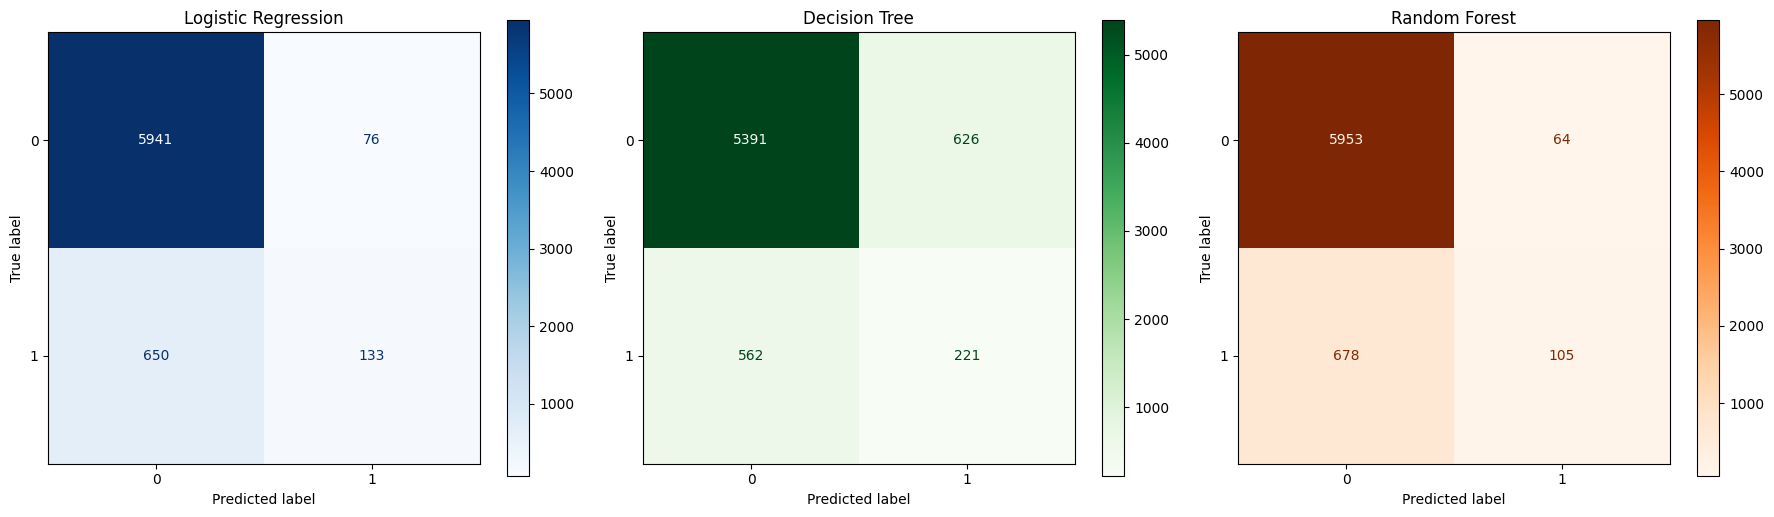

In [45]:
# ALL confusion Matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 1. Logistic Regression Confusion Matrix
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=[0, 1])
disp_lr.plot(ax=ax[0], cmap='Blues', values_format='d')
ax[0].set_title("Logistic Regression")

# 2. Decision Tree Confusion Matrix
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=[0, 1])
disp_dt.plot(ax=ax[1], cmap='Greens', values_format='d')
ax[1].set_title("Decision Tree")

# 3. Random Forest Confusion Matrix
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=[0, 1])
disp_rf.plot(ax=ax[2], cmap='Oranges', values_format='d')
ax[2].set_title("Random Forest")

plt.tight_layout()
plt.show()



> After Evaluating three models I came to conclusion That the Logistics regression model is the best among them. We will move forward with the same.



### Classification Threshold Optimization

In [36]:
# Comparing different Logistic regression Thresholds

from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    y_threshold_pred = (y_pred_proba_lr >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_threshold_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)

,Threshold,Precision,Recall,F1-score
0,0.10,0.261,0.802,0.394
1,0.15,0.325,0.686,0.441
2,0.20,0.372,0.577,0.452
3,0.25,0.411,0.467,0.437
4,0.30,0.458,0.392,0.423
5,0.40,0.551,0.262,0.355
6,0.50,0.636,0.170,0.268


In [37]:
best_threshold = 0.25

print("Selected threshold:", best_threshold)

Selected threshold: 0.25


In [38]:
# Get churn probabilities of selected 0.25 threshold

y_test_proba_lr = lr_model.predict_proba(X_test_transformed)[:, 1]

# Apply our selected threshold
best_threshold = 0.25
y_test_pred = (y_test_proba_lr >= best_threshold).astype(int)

In [39]:
print("Threshold:", best_threshold)
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("\nClassification Report:\n", classification_report(y_test, y_test_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_test_proba_lr))
print("PR-AUC:", average_precision_score(y_test, y_test_proba_lr))

Threshold: 0.25
Accuracy: 0.8614705882352941

Confusion Matrix:
 [[5492  525]
 [ 417  366]]

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.91      0.92      6017
           1       0.41      0.47      0.44       783

    accuracy                           0.86      6800
   macro avg       0.67      0.69      0.68      6800
weighted avg       0.87      0.86      0.87      6800

ROC-AUC: 0.828491475090479
PR-AUC: 0.4336966176852653


* Exporting the model

In [ ]:
import pickle


with open("/models/churn_model.pkl", "wb") as file:
    pickle.dump({
        "model": lr_model,
        "preprocessor": preprocessor,
        "threshold": best_threshold
    }, file)

print("Model, preprocessor, and threshold saved")